# Финмодель «Опыт владельцев» (Авито): графики и регрессионные модели сценариев

Ноутбук читает рассчитанный файл `Avito_finmodel_Opyt_vladeltsev.xlsx` (листы `Модель_Пессимист / База / Оптимист`) и делает три вещи:

1. **Основные графики** — окупаемость, NPV, ROI, пиковое финансирование, структура выручки и затрат, чувствительность. Каждый график в двух версиях: **интерактивный (plotly)** и **статичный (matplotlib)**.
2. **Воспроизведение модели в Python** — проверяем, что расчёт совпадает с Excel до копейки (иначе обучать на нём модели нельзя).
3. **Три линейные регрессии `sklearn`** (отдельная на каждый сценарий): учим «суррогат» Excel-модели предсказывать накопленный чистый поток за 3 года по ключевым драйверам и смотрим, как по-разному сценарии на них реагируют.

Все деньги — млн ₽. Допущения в файле — черновые (кроме цифр кейса), поэтому важна форма графиков, а не конкретные числа.

In [1]:
# Установка зависимостей (запустить один раз)
%pip install -q numpy pandas openpyxl matplotlib plotly scikit-learn nbformat

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, warnings
import numpy as np, pandas as pd
import openpyxl
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

warnings.filterwarnings('ignore')
XLSX = 'Avito_finmodel_Opyt_vladeltsev_tochno.xlsx'
OUT = 'charts_py'
os.makedirs(OUT, exist_ok=True)

SC = ['Пессимист', 'База', 'Оптимист']
COLORS = {'Пессимист': '#D55E00', 'База': '#0072B2', 'Оптимист': '#009E73'}   # палитра Okabe-Ito, различима при дальтонизме
plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'figure.dpi': 110, 'axes.titleweight': 'bold'})

FIGS, KALEIDO = {}, [True]

def pshow(fig, name, title, h=480):
    """Оформить plotly-график, сохранить HTML (и PNG, если доступен kaleido) и показать."""
    fig.update_layout(template='plotly_white', title=dict(text=title, x=0.01), font=dict(family='Arial', size=13),
                      height=h, margin=dict(l=60, r=30, t=80, b=60), legend=dict(orientation='h', y=-0.2))
    FIGS[name] = fig
    fig.write_html(f'{OUT}/{name}.html', include_plotlyjs='cdn')
    if KALEIDO[0]:
        try:
            fig.write_image(f'{OUT}/{name}.png', scale=2, width=1100, height=h)
        except Exception:
            KALEIDO[0] = False   # нет браузера для экспорта PNG — ничего страшного, есть HTML и matplotlib-версии
    fig.show()

def mshow(fig, name):
    fig.tight_layout()
    fig.savefig(f'{OUT}/{name}_static.png', dpi=200, bbox_inches='tight')
    plt.show()

## 1. Загрузка результатов из Excel

In [3]:
wb = openpyxl.load_workbook(XLSX, data_only=True)          # data_only: читаем уже посчитанные значения
SHEET = {s: wb[f'Модель_{s}'] for s in SC}
LBL = {s: {ws.cell(r, 1).value: r for r in range(1, ws.max_row + 1) if ws.cell(r, 1).value} for s, ws in SHEET.items()}

def qs(s, label):   # 12 кварталов: колонки D..O
    r = LBL[s][label]; return np.array([SHEET[s].cell(r, c).value or 0 for c in range(4, 16)], float)
def ys(s, label):   # 3 года: колонки Q..S
    r = LBL[s][label]; return np.array([SHEET[s].cell(r, c).value or 0 for c in range(17, 20)], float)
def val(s, label):  # итоговый показатель: колонка C
    return SHEET[s].cell(LBL[s][label], 3).value

PER = [SHEET['База'].cell(7, c).value for c in range(4, 16)]    # подписи кварталов «Q1 2027» ...
YEARS = [str(SHEET['База'].cell(7, c).value) for c in range(17, 20)]

KPI = {'pq': 'Окупаемость: квартал, когда накопленный поток ≥ 0', 'pqd': 'Дисконтированная окупаемость: квартал, когда накопл. дисконт. поток ≥ 0', 'peak': 'Пиковая потребность в финансировании',
       'trev': 'Дополнительная выручка за 3 года', 'tcost': 'Затраты за 3 года', 'tnet': 'Накопленный чистый поток за 3 года',
       'npv': 'NPV за 3 года', 'roi': 'ROI за 3 года (накопл. чистый поток / затраты)', 'run': 'Run-rate чистого потока на Q12 (×4)',
       'be': 'Мин. прирост конверсии: простая окупаемость за 12 кв.', 'bed': 'Мин. прирост конверсии: дисконтированная окупаемость за 12 кв.',
       'uplift': 'Прирост конверсии в сделку в карточках с блоком (относительный)'}
summ = pd.DataFrame({s: {k: val(s, v) for k, v in KPI.items()} for s in SC}).T
summ['pq'] = pd.to_numeric(summ['pq'], errors='coerce')      # «не окупается» -> NaN
summ['pqd'] = pd.to_numeric(summ['pqd'], errors='coerce')
summ = summ.astype(float)
summ.round(3)

,pq,pqd,peak,trev,tcost,tnet,npv,roi,run,be,bed,uplift
Пессимист,NaN,NaN,478.110,58.038,527.442,-478.110,-381.440,-0.906,-164.155,0.388,0.427,0.04
База,NaN,NaN,170.257,630.449,642.270,-106.388,-106.501,-0.166,66.667,0.061,0.064,0.05
Оптимист,7.0,7.0,146.933,2301.864,927.367,1029.218,714.178,1.110,844.394,0.029,0.031,0.08


## 2. Основные графики (интерактивные plotly + статичные matplotlib)

### 2.1. Накопленный чистый денежный поток — главный график окупаемости
Окупаемость — момент, когда кривая пересекает ноль (ромб). Лимит кейса — 12 кварталов. Сплошная линия — без дисконтирования, пунктир — дисконтированный поток по околоключевой ставке 15% (ключевая ставка ЦБ 14% + 1 п.п.).

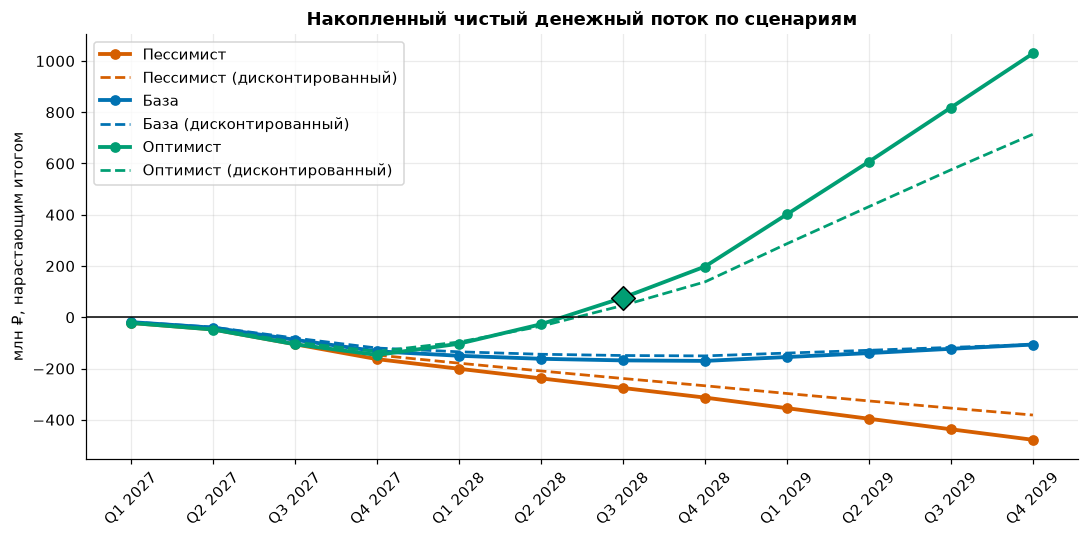

In [4]:
cum = {s: qs(s, 'Накопленный денежный поток') for s in SC}
cumd = {s: qs(s, 'Накопленный дисконтированный поток') for s in SC}    # дисконтирование по околоключевой ставке (15%)

fig = go.Figure()
for s in SC:
    fig.add_scatter(x=PER, y=cum[s], mode='lines+markers', name=s, line=dict(color=COLORS[s], width=3),
                    hovertemplate='%{x}<br>' + s + ': %{y:,.0f} млн ₽<extra></extra>')
    fig.add_scatter(x=PER, y=cumd[s], mode='lines', name=f'{s} (дисконтированный)', line=dict(color=COLORS[s], width=2, dash='dash'),
                    hovertemplate='%{x}<br>' + s + ' дисконт.: %{y:,.0f} млн ₽<extra></extra>')
    if not np.isnan(summ.loc[s, 'pq']):
        k = int(summ.loc[s, 'pq']) - 1
        fig.add_scatter(x=[PER[k]], y=[cum[s][k]], mode='markers', marker=dict(symbol='diamond', size=14, color=COLORS[s], line=dict(width=2, color='black')),
                        name=f'Окупаемость: {s}', hovertemplate=f'Окупился в {PER[k]}<extra></extra>')
fig.add_hline(y=0, line=dict(color='black', width=1))
fig.add_vrect(x0=PER[0], x1=PER[-1], fillcolor='grey', opacity=0.04, line_width=0)
fig.update_yaxes(title='млн ₽, нарастающим итогом'); fig.update_layout(hovermode='x unified')
pshow(fig, 'cum_cashflow', 'Накопленный чистый денежный поток по сценариям')

f, ax = plt.subplots(figsize=(10, 5))
for s in SC:
    ax.plot(PER, cum[s], marker='o', lw=2.5, color=COLORS[s], label=s)
    ax.plot(PER, cumd[s], ls='--', lw=1.8, color=COLORS[s], label=f'{s} (дисконтированный)')
    if not np.isnan(summ.loc[s, 'pq']):
        k = int(summ.loc[s, 'pq']) - 1; ax.scatter(PER[k], cum[s][k], marker='D', s=120, color=COLORS[s], edgecolor='black', zorder=5)
ax.axhline(0, color='black', lw=1); ax.set_ylabel('млн ₽, нарастающим итогом'); ax.set_title('Накопленный чистый денежный поток по сценариям')
ax.tick_params(axis='x', rotation=45); ax.legend(); mshow(f, 'cum_cashflow')

### 2.2. Ключевые показатели: NPV, накопленный поток, пиковое финансирование, ROI

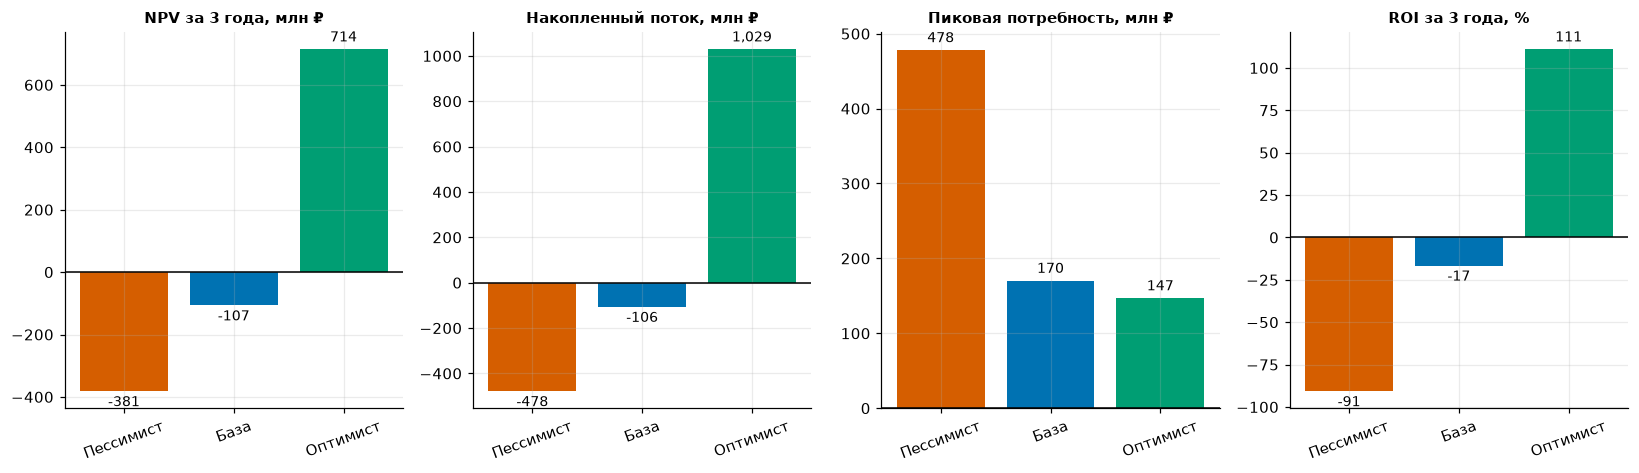

In [5]:
METR = [('npv', 'NPV за 3 года, млн ₽', 1), ('tnet', 'Накопленный поток, млн ₽', 1), ('peak', 'Пиковая потребность, млн ₽', 1), ('roi', 'ROI за 3 года, %', 100)]

fig = make_subplots(rows=1, cols=4, subplot_titles=[m[1] for m in METR], horizontal_spacing=0.07)
for j, (k, t, m) in enumerate(METR, 1):
    v = [summ.loc[s, k] * m for s in SC]
    fig.add_bar(x=SC, y=v, marker_color=[COLORS[s] for s in SC], text=[f'{x:,.0f}' for x in v], textposition='outside', showlegend=False,
                hovertemplate='%{x}: %{y:,.1f}<extra></extra>', row=1, col=j)
    fig.add_hline(y=0, line=dict(color='black', width=1), row=1, col=j)
fig.update_layout(bargap=0.35)
pshow(fig, 'kpi', 'Ключевые финансовые показатели за 3 года', h=440)

f, axs = plt.subplots(1, 4, figsize=(15, 4.4))
for ax, (k, t, m) in zip(axs, METR):
    v = [summ.loc[s, k] * m for s in SC]
    b = ax.bar(SC, v, color=[COLORS[s] for s in SC]); ax.axhline(0, color='black', lw=1); ax.set_title(t, fontsize=10)
    ax.bar_label(b, labels=[f'{x:,.0f}' for x in v], padding=3, fontsize=9); ax.tick_params(axis='x', rotation=20)
mshow(f, 'kpi')

### 2.3. Окупаемость против лимита кейса и «заложено vs нужно» по приросту конверсии
Слева — срок окупаемости (лимит 12 кварталов). Справа — какой прирост конверсии заложен в сценарии и какой нужен, чтобы выйти в ноль за 3 года. Это самый наглядный способ показать, насколько проект зависит от одной гипотезы.

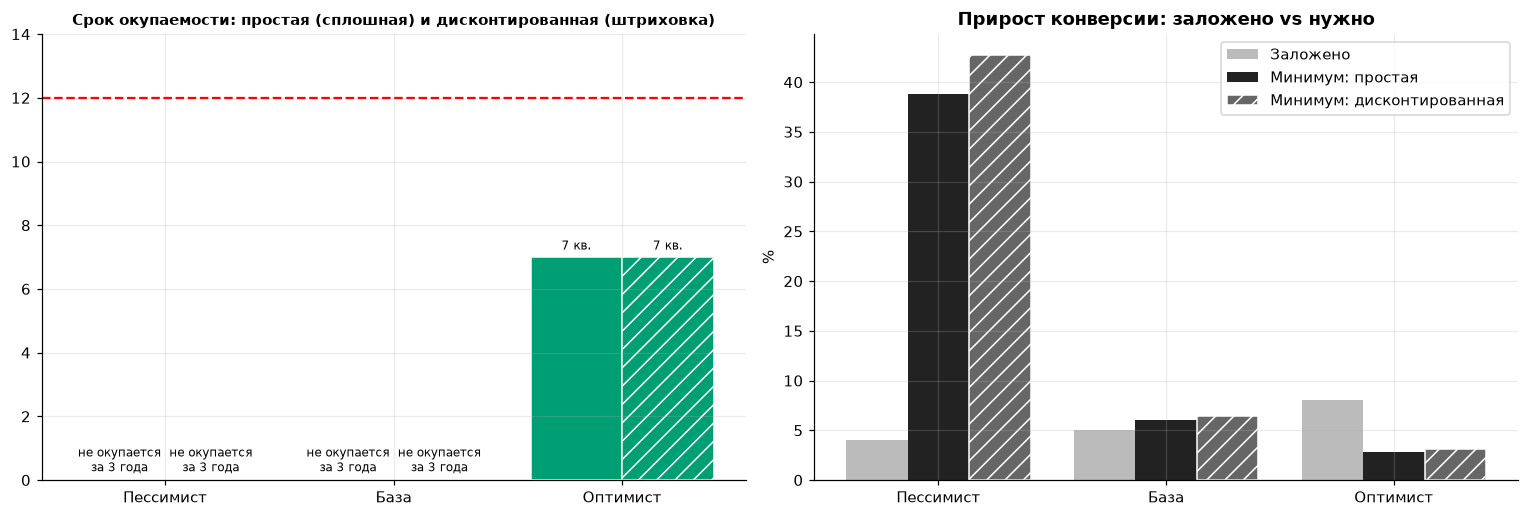

In [6]:
pq, pqd = summ['pq'], summ['pqd']; LIM = 12
lab = lambda v: f'{int(v)} кв.' if v == v else 'не окупается<br>за 3 года'
fig = make_subplots(rows=1, cols=2, subplot_titles=['Срок окупаемости, кварталов (слева простая, справа — дисконтированная; лимит 12)', 'Прирост конверсии: заложено vs минимум для окупаемости за 12 кв.'], horizontal_spacing=0.1)
fig.add_bar(x=SC, y=pq.fillna(0), name='Простая', marker_color=[COLORS[s] for s in SC], text=[lab(v) for v in pq], textposition='outside', showlegend=False, offsetgroup=0, row=1, col=1)
fig.add_bar(x=SC, y=pqd.fillna(0), name='Дисконтированная', marker_color=[COLORS[s] for s in SC], marker_pattern_shape='/', text=[lab(v) for v in pqd], textposition='outside', showlegend=False, offsetgroup=1, row=1, col=1)
fig.add_hline(y=LIM, line=dict(color='red', dash='dash'), row=1, col=1)
fig.add_bar(x=SC, y=summ['uplift'] * 100, name='Заложено', marker_color='#999999', offsetgroup=2, row=1, col=2)
fig.add_bar(x=SC, y=summ['be'] * 100, name='Минимум: простая окупаемость', marker_color='#222222', offsetgroup=3, row=1, col=2)
fig.add_bar(x=SC, y=summ['bed'] * 100, name='Минимум: дисконтированная', marker_color='#666666', offsetgroup=4, row=1, col=2)
fig.update_yaxes(range=[0, 14], row=1, col=1); fig.update_yaxes(title='%', row=1, col=2); fig.update_layout(barmode='group')
pshow(fig, 'payback_breakeven', 'Окупаемость и запас по главной гипотезе', h=470)

f, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8)); x = np.arange(3)
for off, v, hatch, nm in [(-.2, pq, None, 'простая'), (.2, pqd, '//', 'дисконтированная')]:
    b = a1.bar(x + off, v.fillna(0), .4, color=[COLORS[s] for s in SC], hatch=hatch, edgecolor='white', label=nm)
    a1.bar_label(b, labels=[f'{int(t)} кв.' if t == t else 'не окупается\nза 3 года' for t in v], padding=3, fontsize=8)
a1.axhline(LIM, color='red', ls='--'); a1.set_ylim(0, 14); a1.set_xticks(x, SC); a1.set_title('Срок окупаемости: простая (сплошная) и дисконтированная (штриховка)', fontsize=10)
a2.bar(x - .27, summ['uplift'] * 100, .27, color='#BBBBBB', label='Заложено'); a2.bar(x, summ['be'] * 100, .27, color='#222222', label='Минимум: простая'); a2.bar(x + .27, summ['bed'] * 100, .27, color='#666666', hatch='//', edgecolor='white', label='Минимум: дисконтированная')
a2.set_xticks(x, SC); a2.set_ylabel('%'); a2.legend(); a2.set_title('Прирост конверсии: заложено vs нужно'); mshow(f, 'payback_breakeven')

### 2.4. Чистый денежный поток по кварталам

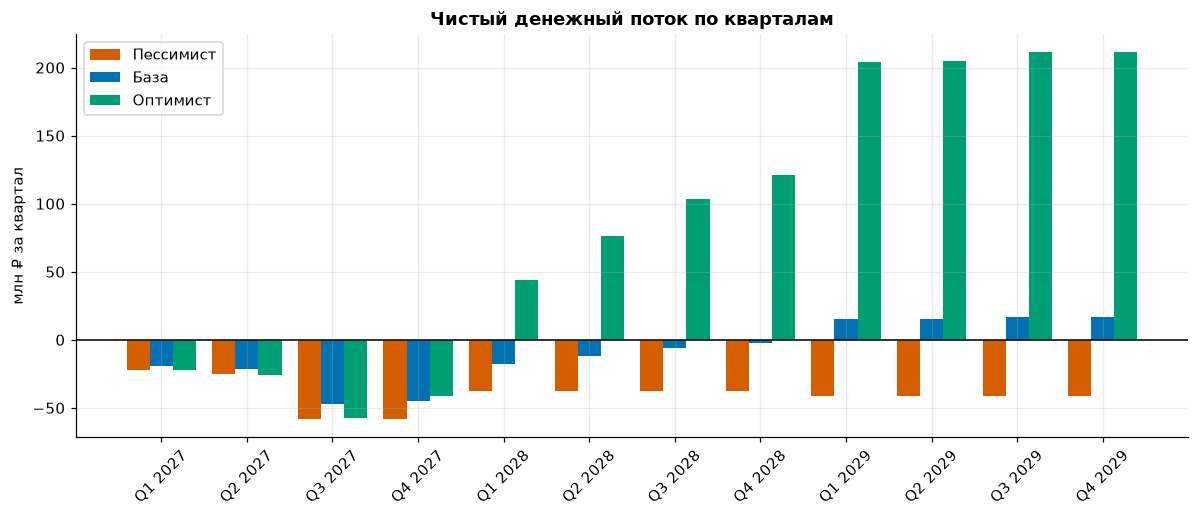

In [7]:
net = {s: qs(s, 'Чистый денежный поток') for s in SC}
fig = go.Figure()
for s in SC:
    fig.add_bar(x=PER, y=net[s], name=s, marker_color=COLORS[s], hovertemplate='%{x}: %{y:,.1f} млн ₽<extra>' + s + '</extra>')
fig.add_hline(y=0, line=dict(color='black', width=1)); fig.update_layout(barmode='group'); fig.update_yaxes(title='млн ₽ за квартал')
pshow(fig, 'net_quarterly', 'Чистый денежный поток по кварталам')

f, ax = plt.subplots(figsize=(11, 4.8)); w = .27
for i, s in enumerate(SC): ax.bar(np.arange(12) + (i - 1) * w, net[s], w, color=COLORS[s], label=s)
ax.axhline(0, color='black', lw=1); ax.set_xticks(range(12), PER, rotation=45); ax.set_ylabel('млн ₽ за квартал'); ax.set_title('Чистый денежный поток по кварталам'); ax.legend(); mshow(f, 'net_quarterly')

### 2.5. Откуда выручка и куда уходят деньги (по годам)

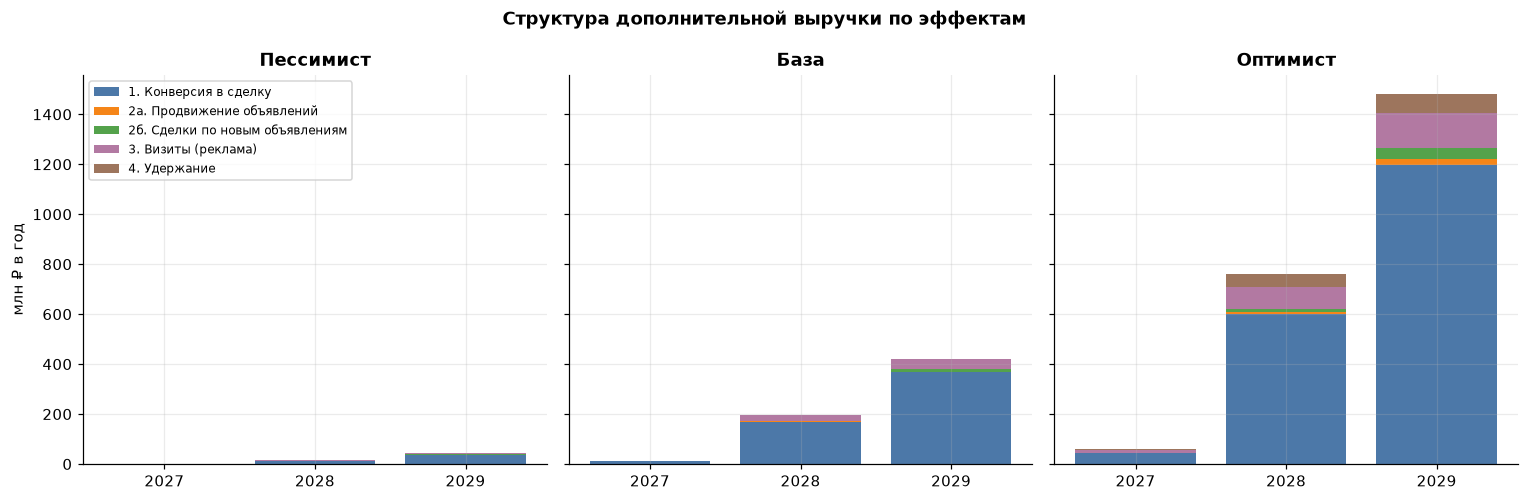

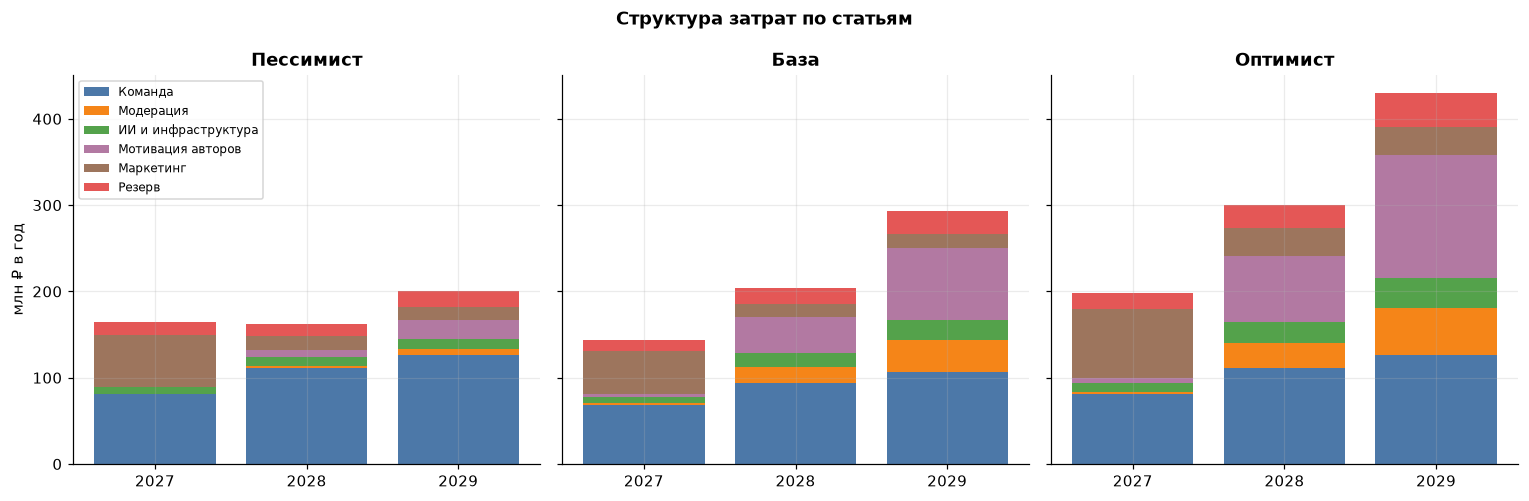

In [8]:
REV = {'Эффект 1: доход от конверсии (комиссия Доставки)': '1. Конверсия в сделку', 'Эффект 2: доход от продвижения новых объявлений': '2а. Продвижение объявлений',
       'Эффект 2: доход со сделок по новым объявлениям': '2б. Сделки по новым объявлениям', 'Эффект 3: доход от рекламы и рекомендаций': '3. Визиты (реклама)',
       'Эффект 4: удержание (верхний сценарий)': '4. Удержание'}
COST = {'Команда разработки': 'Команда', 'ИИ-модерация': 'Модерация', 'Ручная модерация спорных случаев': 'Модерация', 'ИИ и инфраструктура': 'ИИ и инфраструктура',
        'Мотивация авторов (с годовым потолком)': 'Мотивация авторов', 'Маркетинг (запуск + текущий)': 'Маркетинг', 'Резерв': 'Резерв'}
PAL = ['#4C78A8', '#F58518', '#54A24B', '#B279A2', '#9D755D', '#E45756']

def stack(mapping):
    out = {}
    for s in SC:
        d = {}
        for lab, nm in mapping.items(): d[nm] = d.get(nm, 0) + ys(s, lab)
        out[s] = d
    return out
RV, CS = stack(REV), stack(COST)

def stacked(data, name, title, ylab):
    fig = make_subplots(rows=1, cols=3, subplot_titles=SC, shared_yaxes=True, horizontal_spacing=0.03)
    comps = list(data['База'].keys())
    for j, s in enumerate(SC, 1):
        for k, c in enumerate(comps):
            fig.add_bar(x=YEARS, y=data[s][c], name=c, marker_color=PAL[k], legendgroup=c, showlegend=(j == 1), row=1, col=j)
    fig.update_layout(barmode='stack'); fig.update_yaxes(title=ylab, row=1, col=1)
    pshow(fig, name, title, h=470)
    f, axs = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
    for ax, s in zip(axs, SC):
        bot = np.zeros(3)
        for k, c in enumerate(comps): ax.bar(YEARS, data[s][c], bottom=bot, color=PAL[k], label=c); bot += data[s][c]
        ax.set_title(s)
    axs[0].set_ylabel(ylab); axs[0].legend(fontsize=8, loc='upper left'); f.suptitle(title, fontweight='bold'); mshow(f, name)

stacked(RV, 'revenue_structure', 'Структура дополнительной выручки по эффектам', 'млн ₽ в год')
stacked(CS, 'cost_structure', 'Структура затрат по статьям', 'млн ₽ в год')

### 2.6. Чувствительность накопленного потока к приросту конверсии
Таблица из листа «Сводка» (блок 3). Точка пересечения с нулём — критический прирост конверсии для каждого сценария.

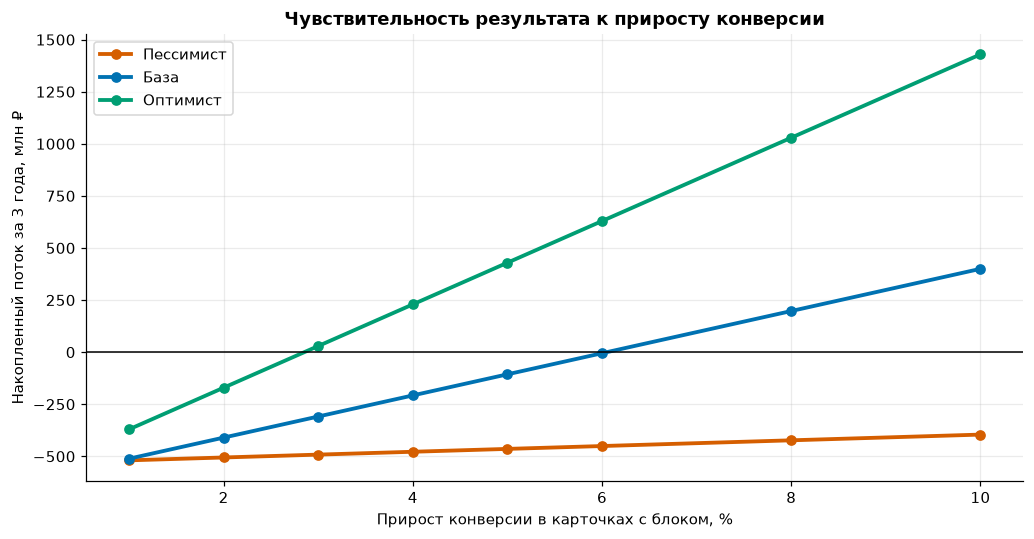

In [9]:
S = wb['Сводка']
r0 = next(r for r in range(1, S.max_row + 1) if str(S.cell(r, 1).value or '').startswith('3. Чувствительность')) + 2
sens = pd.DataFrame([[S.cell(r, c).value for c in range(1, 5)] for r in range(r0, r0 + 8)], columns=['uplift'] + SC)

fig = go.Figure()
for s in SC: fig.add_scatter(x=sens['uplift'] * 100, y=sens[s], mode='lines+markers', name=s, line=dict(color=COLORS[s], width=3))
fig.add_hline(y=0, line=dict(color='black', width=1)); fig.update_xaxes(title='Прирост конверсии в карточках с блоком, %'); fig.update_yaxes(title='Накопленный поток за 3 года, млн ₽')
pshow(fig, 'sensitivity_uplift', 'Чувствительность результата к приросту конверсии')

f, ax = plt.subplots(figsize=(9.5, 5))
for s in SC: ax.plot(sens['uplift'] * 100, sens[s], marker='o', lw=2.5, color=COLORS[s], label=s)
ax.axhline(0, color='black', lw=1); ax.set_xlabel('Прирост конверсии в карточках с блоком, %'); ax.set_ylabel('Накопленный поток за 3 года, млн ₽')
ax.set_title('Чувствительность результата к приросту конверсии'); ax.legend(); mshow(f, 'sensitivity_uplift')

## 3. Воспроизводим модель в Python

Чтобы обучать регрессию, нужно много прогонов модели с разными входами, а Excel для этого неудобен. Поэтому пишем точную копию расчёта и **сверяем её с Excel** по накопленному потоку, NPV и выручке для всех трёх сценариев. Параметры читаются прямо с листа «Допущения».

In [10]:
wa = wb['Допущения']
AR = {wa.cell(r, 1).value: r for r in range(1, wa.max_row + 1) if wa.cell(r, 1).value}
PL = {
 'disc': 'Ставка дисконтирования (годовая)', 'margin': 'Маржа инкрементального дохода (после переменных издержек сделок)',
 'deals_base': 'Товарные сделки на платформе в год (база 2026)', 'deals_g': 'Рост числа товарных сделок в год',
 'chk_idx': 'Индексация среднего чека и комиссии в год (сложный процент)',
 'ds_start': 'Доля товарных сделок с Авито Доставкой (2026)', 'ds_pp': 'Рост доли Доставки в год', 'mau': 'Месячная аудитория Авито',
 'cov1': 'Доля сделок Доставки в охваченных категориях — Год 1', 'cov2': 'то же — Год 2', 'cov3': 'то же — Год 3',
 'card_peak': 'Доля сделок, идущих через карточки с блоком опыта (на зрелости)',
 'review_rate': 'Доля подтверждённых покупателей, оставивших отзыв о модели (на зрелости)',
 'upd_share': 'Доля авторов, обновивших отзыв позже / с долгим сроком использования', 'lag': 'Срок использования до пуша «оцените и продайте»',
 'list_share': 'Доля обновивших отзыв, выставивших вещь через «Можно продать»', 'promo_share': 'Доля выставивших вещь, купивших продвижение',
 'promo_arpu': 'Средний платёж за продвижение', 'sale_prob': 'Доля выставленных вещей, проданных через Доставку',
 'uplift': 'Прирост конверсии в сделку в карточках с блоком (относительный)',
 'neg': 'Негативный эффект: потеря сделок в охваченных карточках (слабые модели, меньше контактов)',
 'incr': 'Доля прироста, действительно инкрементальная', 'avg_check': 'Средний чек сделки с Доставкой', 'take': 'Доход Авито с оборота сделки через Доставку',
 'reach': 'Доля аудитории охваченных категорий, пользующаяся блоком в месяц (на зрелости)', 'visits': 'Дополнительных визитов на участника в месяц',
 'views': 'Просмотров за дополнительный визит', 'ad_view': 'Доход от рекламы и рекомендаций на один просмотр',
 'ret_deals': 'Доп. сделок в год на участника за счёт удержания (по всей платформе)', 'plat_income': 'Средний доход Авито со сделки на платформе',
 'rate': 'Стоимость 1 FTE в месяц (с налогами и накладными)', 'idx': 'Индексация ФОТ в год', 'msgs': 'Сообщений в обсуждениях на один отзыв',
 'ai_mod': 'Стоимость ИИ-модерации одного объекта', 'man_share': 'Доля спорных объектов (ручная проверка)', 'man_cost': 'Стоимость ручной проверки',
 'ai_gen': 'ИИ: генерация пересказов и ИИ-ответов, на 1 отзыв', 'infra_fixed': 'Инфраструктура и хранение (фикс.) в квартал',
 'infra_start': 'Первый квартал инфраструктурных затрат', 'bonus_share': 'Доля отзывов, получающих бонус/пожертвование',
 'bonus_amt': 'Сумма бонуса/пожертвования за отзыв', 'bonus_cap': 'Годовой потолок бюджета на мотивацию', 'cont': 'Резерв на непредвиденные затраты',
 'mk_launch': 'Разовый маркетинг запуска', 'mk_s': 'Первый квартал маркетинга запуска', 'mk_e': 'Последний квартал маркетинга запуска',
 'mk_ongoing': 'Текущий маркетинг и тесты после запуска, в квартал', 'fte_mult': 'Коэффициент к численности команды'}

def base_params(i):   # i = 0,1,2 -> Пессимист, База, Оптимист
    p = {k: float(wa.cell(AR[v], 3 + i).value) for k, v in PL.items()}
    p['cov'] = [p.pop('cov1'), p.pop('cov2'), p.pop('cov3')]
    p['fte'] = [float(wa.cell(AR['Итого FTE (база)'], 3 + y).value) * p['fte_mult'] for y in range(3)]
    p['ramp'] = np.array([float(wa.cell(AR[f'Профиль зрелости — {SC[i]}'], 4 + q).value) for q in range(12)])
    return p

def run(p):
    n = 12; reviews = np.zeros(n); rev = np.zeros(n); cost = np.zeros(n); lag = int(round(p['lag']))
    for i in range(1, n + 1):
        k, y = i - 1, (i + 3) // 4
        income = p['avg_check'] * p['take'] * (1 + p['chk_idx']) ** (y - 1)   # сложный процент: индексация чека и комиссии
        deals = p['deals_base'] * 1000 * (1 + p['deals_g']) ** y / 4
        cd = deals * (p['ds_start'] + p['ds_pp'] * y) * p['cov'][y - 1]
        ramp = p['ramp'][k]; card = cd * p['card_peak'] * ramp
        reviews[k] = cd * ramp * p['review_rate']
        upd = reviews[i - 1 - lag] * p['upd_share'] if i > lag else 0.0
        lst = upd * p['list_share']; promo = lst * p['promo_share']
        netdeals = card * p['uplift'] * p['incr'] - card * p['neg']
        part = p['mau'] * 1000 * p['cov'][y - 1] * p['reach'] * ramp
        r1 = netdeals * income / 1000
        r2 = promo * p['promo_arpu'] / 1000 + lst * p['sale_prob'] * income / 1000
        r3 = part * p['visits'] * 3 * p['views'] * p['ad_view'] / 1000
        r4 = part * p['ret_deals'] / 4 * p['plat_income'] / 1000
        rev[k] = r1 + r2 + r3 + r4
        team = p['fte'][y - 1] * p['rate'] * 3 * (1 + p['idx']) ** (y - 1) / 1000
        items = reviews[k] * (1 + p['msgs'])
        mod = items * p['ai_mod'] / 1000 + items * p['man_share'] * p['man_cost'] / 1000
        ai = reviews[k] * p['ai_gen'] / 1000 + (p['infra_fixed'] if i >= p['infra_start'] else 0)
        bonus = min(reviews[k] * p['bonus_share'] * p['bonus_amt'] / 1000, p['bonus_cap'] / 4)
        mkt = (p['mk_launch'] / (p['mk_e'] - p['mk_s'] + 1) if p['mk_s'] <= i <= p['mk_e'] else 0) + (p['mk_ongoing'] if i > p['mk_e'] else 0)
        cost[k] = (team + mod + ai + bonus + mkt) * (1 + p['cont'])
    net = rev * p['margin'] - cost
    cumf = np.cumsum(net)
    dcf = net / (1 + p['disc']) ** (np.arange(1, n + 1) / 4)
    return dict(rev=rev, cost=cost, net=net, cum=cumf, npv=float(dcf.sum()), cumd=np.cumsum(dcf))

chk = []
for i, s in enumerate(SC):
    r = run(base_params(i))
    pqd_py = next((q + 1 for q, v in enumerate(r['cumd']) if v >= 0), np.nan)
    assert (np.isnan(pqd_py) and np.isnan(summ.loc[s, 'pqd'])) or pqd_py == summ.loc[s, 'pqd'], s
    chk.append([s, r['cum'][-1], summ.loc[s, 'tnet'], r['npv'], summ.loc[s, 'npv'], r['rev'].sum(), summ.loc[s, 'trev']])
    assert np.isclose(r['cum'][-1], summ.loc[s, 'tnet'], atol=1e-6) and np.isclose(r['npv'], summ.loc[s, 'npv'], atol=1e-6) and np.isclose(r['rev'].sum(), summ.loc[s, 'trev'], atol=1e-6), s
pd.DataFrame(chk, columns=['Сценарий', 'Накопл. поток (Python)', 'Накопл. поток (Excel)', 'NPV (Python)', 'NPV (Excel)', 'Выручка (Python)', 'Выручка (Excel)']).round(3)

,Сценарий,Накопл. поток (Python),Накопл. поток (Excel),NPV (Python),NPV (Excel),Выручка (Python),Выручка (Excel)
0,Пессимист,-478.110,-478.110,-381.440,-381.440,58.038,58.038
1,База,-106.388,-106.388,-106.501,-106.501,630.449,630.449
2,Оптимист,1029.218,1029.218,714.178,714.178,2301.864,2301.864


## 4. Три линейные регрессии — по одной на сценарий

**Идея.** Excel-модель — цепочка перемножений, и для презентации хочется простого ответа: «на сколько млн ₽ изменится результат, если драйвер вырастет на 1%». Для этого строим *метамодель* (суррогат):

* для каждого сценария берём его точку допущений и 3 000 раз случайно «трясём» 13 ключевых драйверов в диапазоне **±25%** от значения сценария;
* для каждого набора прогоняем модель (п. 3) и получаем накопленный чистый поток за 3 года;
* обучаем `sklearn.linear_model.LinearRegression`: **признаки** — отклонение драйвера в % от значения сценария, **цель** — накопленный поток за 3 года (млн ₽). 80% данных — обучение, 20% — тест.

Коэффициент регрессии читается напрямую: *«+1% к драйверу → +N млн ₽ накопленного потока»*. Поскольку у каждого сценария своя исходная точка, у трёх моделей получаются **разные интерсепты и разные наклоны** — это и показывает, как сценарии по-разному реагируют на одни и те же драйверы.

In [11]:
DRV = {'uplift': 'Прирост конверсии', 'incr': 'Доля инкрементальных сделок', 'avg_check': 'Средний чек', 'take': 'Доход Авито с оборота',
       'review_rate': 'Доля оставивших отзыв', 'card_peak': 'Доля карточек с блоком', 'cov_scale': 'Охват категорий', 'ramp_scale': 'Скорость выхода на зрелость',
       'reach': 'Доля аудитории, пользующейся блоком', 'visits': 'Доп. визиты на участника', 'list_share': 'Доля выставивших вещь',
       'margin': 'Маржа дохода', 'rate': 'Стоимость FTE'}
KEYS = list(DRV)

def apply(p0, mult):
    p = dict(p0); p['cov'] = [min(1.0, c * mult['cov_scale']) for c in p0['cov']]; p['ramp'] = np.minimum(1.0, p0['ramp'] * mult['ramp_scale'])
    for k in ['uplift', 'avg_check', 'take', 'review_rate', 'reach', 'visits', 'list_share', 'rate']: p[k] = p0[k] * mult[k]
    for k in ['incr', 'card_peak', 'margin']: p[k] = min(1.0, p0[k] * mult[k])    # доли не могут превышать 100%
    return p

N, SPREAD = 3000, 25
rng = np.random.default_rng(42)
DATA = {}
for i, s in enumerate(SC):
    p0 = base_params(i)
    dev = rng.uniform(-SPREAD, SPREAD, size=(N, len(KEYS)))              # отклонения драйверов, %
    y = np.array([run(apply(p0, {k: 1 + d / 100 for k, d in zip(KEYS, row)}))['cum'][-1] for row in dev])
    DATA[s] = (pd.DataFrame(dev, columns=[DRV[k] for k in KEYS]), pd.Series(y, name='Накопл. поток за 3 года, млн ₽'))

MODELS, RES = {}, []
for s in SC:
    X, y = DATA[s]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=7)
    m = LinearRegression().fit(Xtr, ytr); pr = m.predict(Xte); MODELS[s] = (m, Xte, yte, pr)
    RES.append([s, m.intercept_, r2_score(yte, pr), mean_absolute_error(yte, pr), y.mean(), y.std(), (y > 0).mean()])
res = pd.DataFrame(RES, columns=['Сценарий', 'Интерсепт (=результат в точке сценария), млн ₽', 'R² на тесте', 'MAE на тесте, млн ₽', 'Среднее по выборке, млн ₽', 'Ст. откл., млн ₽', 'Доля прогонов с накопл. потоком > 0']).set_index('Сценарий')
res.round(3)

,"Интерсепт (=результат в точке сценария), млн ₽",R² на тесте,"MAE на тесте, млн ₽","Среднее по выборке, млн ₽","Ст. откл., млн ₽",Доля прогонов с накопл. потоком > 0
Сценарий,,,,,,
Пессимист,-478.354,0.988,4.056,-478.769,53.378,0.000
База,-123.023,0.946,30.831,-121.283,185.091,0.236
Оптимист,932.650,0.935,111.211,933.606,622.288,0.979


### 4.1. Качество моделей: предсказание vs факт на тесте
Чем ближе точки к диагонали, тем лучше линейная модель повторяет Excel. Систематический изгиб — там, где сказывается нелинейность (перемножение драйверов и потолки в 100%).

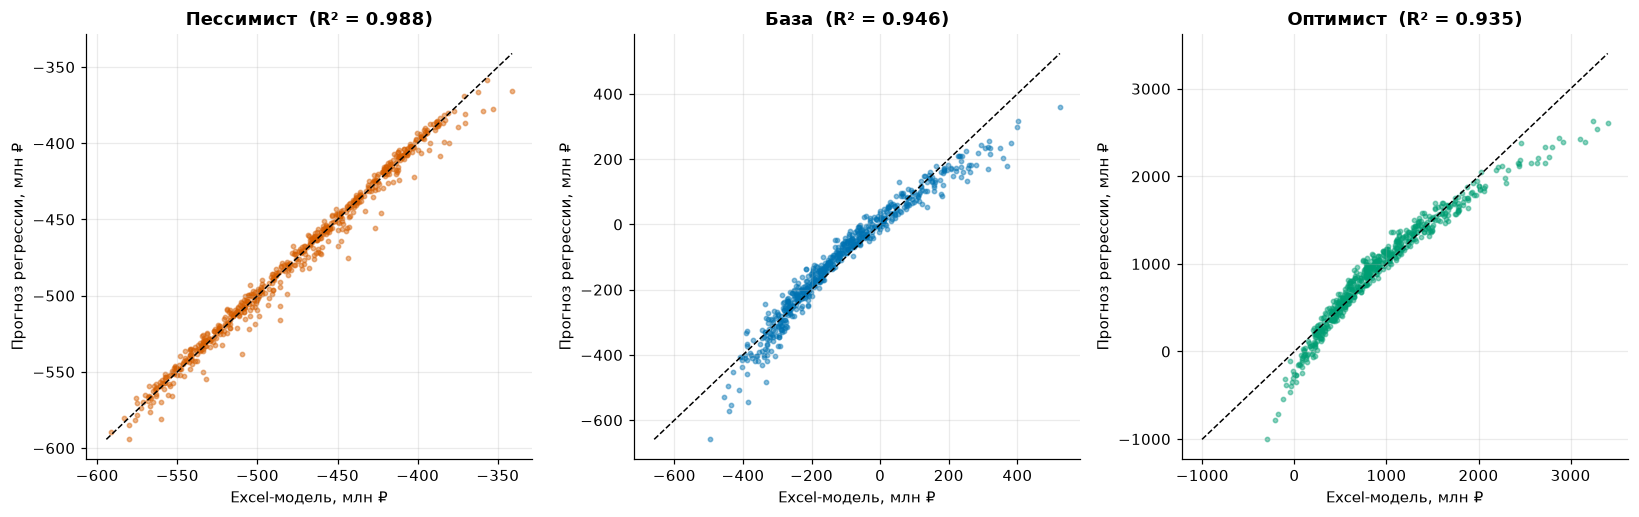

In [12]:
fig = make_subplots(rows=1, cols=3, subplot_titles=[f'{s}  (R² = {r2_score(MODELS[s][2], MODELS[s][3]):.3f})' for s in SC], horizontal_spacing=0.07)
for j, s in enumerate(SC, 1):
    m, Xte, yte, pr = MODELS[s]; lo, hi = min(yte.min(), pr.min()), max(yte.max(), pr.max())
    fig.add_scatter(x=yte, y=pr, mode='markers', marker=dict(color=COLORS[s], size=5, opacity=.5), showlegend=False, hovertemplate='факт %{x:,.0f}<br>прогноз %{y:,.0f}<extra></extra>', row=1, col=j)
    fig.add_scatter(x=[lo, hi], y=[lo, hi], mode='lines', line=dict(color='black', dash='dash'), showlegend=False, row=1, col=j)
    fig.update_xaxes(title='Excel-модель, млн ₽', row=1, col=j)
fig.update_yaxes(title='Прогноз регрессии, млн ₽', row=1, col=1)
pshow(fig, 'lr_pred_vs_actual', 'Три линейные регрессии: прогноз vs расчёт модели (тестовая выборка)', h=460)

f, axs = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, s in zip(axs, SC):
    m, Xte, yte, pr = MODELS[s]; lo, hi = min(yte.min(), pr.min()), max(yte.max(), pr.max())
    ax.scatter(yte, pr, s=8, alpha=.45, color=COLORS[s]); ax.plot([lo, hi], [lo, hi], 'k--', lw=1)
    ax.set_title(f'{s}  (R² = {r2_score(yte, pr):.3f})'); ax.set_xlabel('Excel-модель, млн ₽'); ax.set_ylabel('Прогноз регрессии, млн ₽')
mshow(f, 'lr_pred_vs_actual')

### 4.2. Что двигает результат: коэффициенты трёх моделей
Столбец = на сколько млн ₽ меняется накопленный поток за 3 года при росте драйвера на **1%** (от значения сценария). Сравнение трёх сценариев показывает, что в оптимистичном сценарии «цена» каждого процента выше — там больше объёмы.

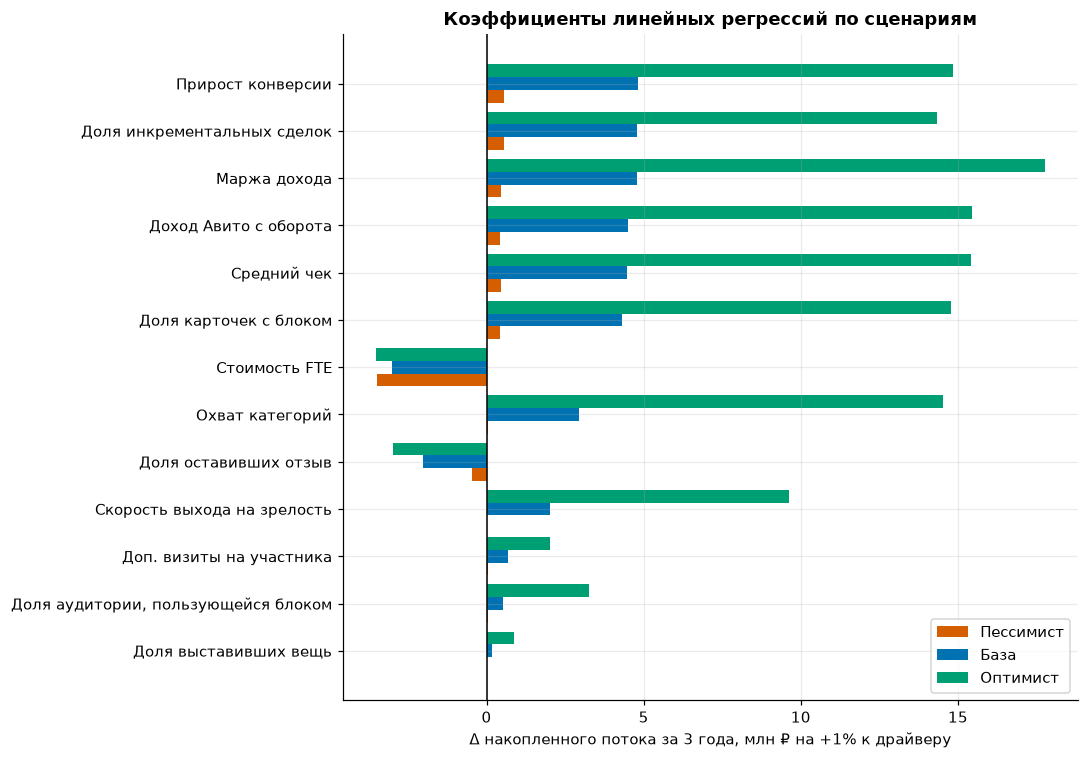

,Пессимист,База,Оптимист
Прирост конверсии,0.55,4.80,14.83
Доля инкрементальных сделок,0.55,4.80,14.33
Маржа дохода,0.47,4.79,17.76
Доход Авито с оборота,0.43,4.49,15.46
Средний чек,0.45,4.46,15.41
Доля карточек с блоком,0.44,4.32,14.77
Охват категорий,0.04,2.93,14.52
Скорость выхода на зрелость,0.03,2.01,9.64
Доп. визиты на участника,0.04,0.68,2.01
"Доля аудитории, пользующейся блоком",0.05,0.53,3.25


In [13]:
coef = pd.DataFrame({s: MODELS[s][0].coef_ for s in SC}, index=[DRV[k] for k in KEYS])
order = coef['База'].abs().sort_values().index; coef = coef.loc[order]

fig = go.Figure()
for s in SC: fig.add_bar(y=coef.index, x=coef[s], name=s, orientation='h', marker_color=COLORS[s], hovertemplate='%{y}<br>%{x:,.2f} млн ₽ на +1%<extra>' + s + '</extra>')
fig.update_layout(barmode='group'); fig.update_xaxes(title='Δ накопленного потока за 3 года, млн ₽ на +1% к драйверу')
pshow(fig, 'lr_coefficients', 'Чувствительность к драйверам: коэффициенты линейных регрессий', h=640)

f, ax = plt.subplots(figsize=(10, 7)); h = .27
for i, s in enumerate(SC): ax.barh(np.arange(len(coef)) + (i - 1) * h, coef[s], h, color=COLORS[s], label=s)
ax.set_yticks(range(len(coef)), coef.index); ax.axvline(0, color='black', lw=1); ax.legend()
ax.set_xlabel('Δ накопленного потока за 3 года, млн ₽ на +1% к драйверу'); ax.set_title('Коэффициенты линейных регрессий по сценариям'); mshow(f, 'lr_coefficients')
coef.sort_values('База', ascending=False).round(2)

### 4.3. Разброс результатов по сценариям
Гистограммы показывают, что будет, если драйверы отклонятся от своих значений на ±25%. Красная линия — ноль (точка окупаемости к 12-му кварталу).

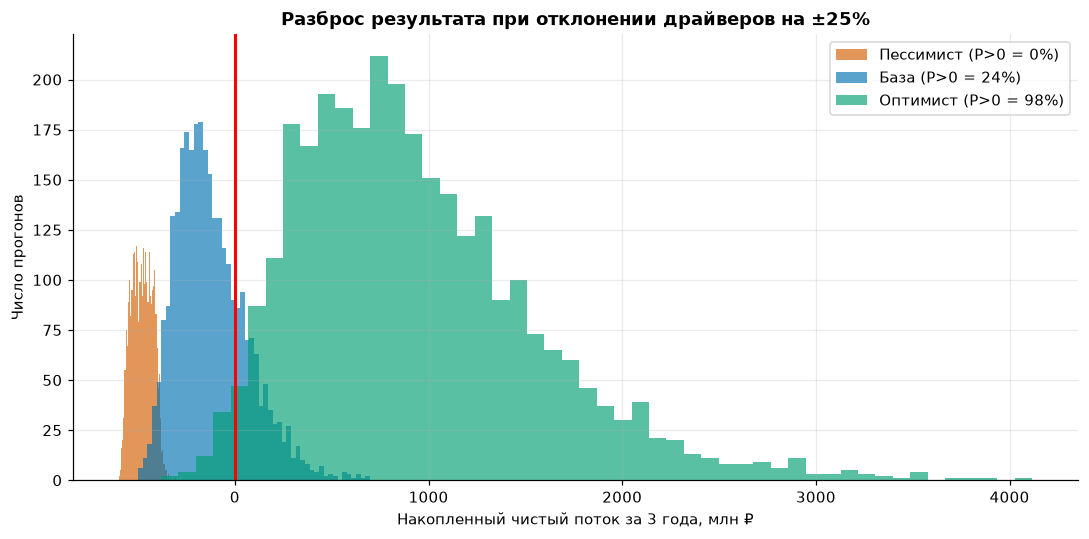

In [14]:
fig = go.Figure()
for s in SC: fig.add_histogram(x=DATA[s][1], name=s, marker_color=COLORS[s], opacity=.65, nbinsx=50, hovertemplate='%{x:,.0f} млн ₽: %{y} прогонов<extra>' + s + '</extra>')
fig.add_vline(x=0, line=dict(color='red', width=2)); fig.update_layout(barmode='overlay'); fig.update_xaxes(title='Накопленный чистый поток за 3 года, млн ₽'); fig.update_yaxes(title='Число прогонов')
pshow(fig, 'lr_distribution', 'Разброс результата при отклонении драйверов на ±25% (3 000 прогонов на сценарий)')

f, ax = plt.subplots(figsize=(10, 5))
for s in SC: ax.hist(DATA[s][1], bins=50, alpha=.65, color=COLORS[s], label=f'{s} (P>0 = {(DATA[s][1] > 0).mean():.0%})')
ax.axvline(0, color='red', lw=2); ax.set_xlabel('Накопленный чистый поток за 3 года, млн ₽'); ax.set_ylabel('Число прогонов'); ax.legend(); ax.set_title('Разброс результата при отклонении драйверов на ±25%'); mshow(f, 'lr_distribution')

### 4.4. Три модели на одном графике: как меняется результат с главным драйвером
Берём каждую обученную регрессию и двигаем **только прирост конверсии** (остальное — как в сценарии). Прямые — прогноз линейных моделей, точки — «настоящий» расчёт Excel-модели. Где прямая пересекает ноль, там критический прирост конверсии.

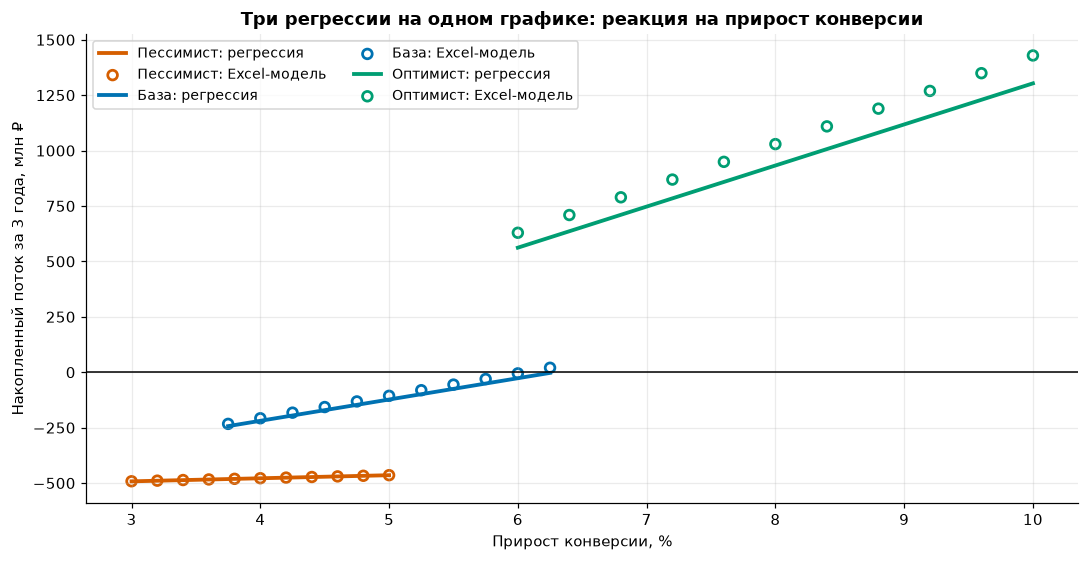

,"Прирост конверсии для выхода в 0 (по регрессии, при прочих драйверах сценария)"
Пессимист,38.5%
База,6.3%
Оптимист,3.0%


In [15]:
iu = KEYS.index('uplift'); grid = np.linspace(-SPREAD, SPREAD, 11); lines, pts, cross = {}, {}, {}
for i, s in enumerate(SC):
    m = MODELS[s][0]; p0 = base_params(i); u0 = p0['uplift'] * 100
    x_abs = u0 * (1 + grid / 100)
    lines[s] = (x_abs, m.intercept_ + m.coef_[iu] * grid)
    pts[s] = (x_abs, [run(apply(p0, {**{k: 1 for k in KEYS}, 'uplift': 1 + d / 100}))['cum'][-1] for d in grid])
    cross[s] = u0 * (1 - m.intercept_ / m.coef_[iu] / 100)       # абсолютный uplift, при котором прогноз = 0

fig = go.Figure()
for s in SC:
    fig.add_scatter(x=lines[s][0], y=lines[s][1], mode='lines', name=f'{s}: регрессия', line=dict(color=COLORS[s], width=3))
    fig.add_scatter(x=pts[s][0], y=pts[s][1], mode='markers', name=f'{s}: Excel-модель', marker=dict(color=COLORS[s], size=8, symbol='circle-open', line=dict(width=2)))
fig.add_hline(y=0, line=dict(color='black', width=1)); fig.update_xaxes(title='Прирост конверсии, %'); fig.update_yaxes(title='Накопленный поток за 3 года, млн ₽')
pshow(fig, 'lr_scenarios_uplift', 'Три регрессии на одном графике: реакция на прирост конверсии', h=500)

f, ax = plt.subplots(figsize=(10, 5.2))
for s in SC:
    ax.plot(*lines[s], lw=2.5, color=COLORS[s], label=f'{s}: регрессия'); ax.scatter(*pts[s], s=40, facecolors='none', edgecolors=COLORS[s], linewidths=1.8, label=f'{s}: Excel-модель')
ax.axhline(0, color='black', lw=1); ax.set_xlabel('Прирост конверсии, %'); ax.set_ylabel('Накопленный поток за 3 года, млн ₽'); ax.legend(ncol=2, fontsize=9)
ax.set_title('Три регрессии на одном графике: реакция на прирост конверсии'); mshow(f, 'lr_scenarios_uplift')
pd.Series({s: f'{cross[s]:.1f}%' for s in SC}, name='Прирост конверсии для выхода в 0 (по регрессии, при прочих драйверах сценария)').to_frame()

## 5. Итоги и выгрузка

In [16]:
print('Сводка по сценариям (расчёт Excel-модели):')
display(summ[['pq', 'peak', 'tnet', 'npv', 'roi', 'be', 'bed']].rename(columns={'pq': 'Окупаемость, кв.', 'peak': 'Пик финансирования', 'tnet': 'Накопл. поток', 'npv': 'NPV', 'roi': 'ROI', 'be': 'Мин. uplift (простая)', 'bed': 'Мин. uplift (дисконт.)'}).round(3))
print('\nМетамодели (LinearRegression):')
display(res.round(3))

# единый офлайн-дашборд со всеми интерактивными графиками (plotly.js вшит в файл — открывается без интернета)
parts = [f.to_html(full_html=False, include_plotlyjs=(i == 0)) for i, f in enumerate(FIGS.values())]
html = '<html><head><meta charset="utf-8"><title>Финмодель Опыт владельцев — графики</title></head><body style="font-family:Arial;max-width:1150px;margin:auto">' + '<hr>'.join(parts) + '</body></html>'
open(f'{OUT}/dashboard_all.html', 'w', encoding='utf-8').write(html)
print('\nФайлы:', sorted(os.listdir(OUT)))

Сводка по сценариям (расчёт Excel-модели):


,"Окупаемость, кв.",Пик финансирования,Накопл. поток,NPV,ROI,Мин. uplift (простая),Мин. uplift (дисконт.)
Пессимист,NaN,478.110,-478.110,-381.440,-0.906,0.388,0.427
База,NaN,170.257,-106.388,-106.501,-0.166,0.061,0.064
Оптимист,7.0,146.933,1029.218,714.178,1.110,0.029,0.031



Метамодели (LinearRegression):


,"Интерсепт (=результат в точке сценария), млн ₽",R² на тесте,"MAE на тесте, млн ₽","Среднее по выборке, млн ₽","Ст. откл., млн ₽",Доля прогонов с накопл. потоком > 0
Сценарий,,,,,,
Пессимист,-478.354,0.988,4.056,-478.769,53.378,0.000
База,-123.023,0.946,30.831,-121.283,185.091,0.236
Оптимист,932.650,0.935,111.211,933.606,622.288,0.979



Файлы: ['cost_structure.html', 'cost_structure_static.png', 'cum_cashflow.html', 'cum_cashflow_static.png', 'dashboard_all.html', 'kpi.html', 'kpi_static.png', 'lr_coefficients.html', 'lr_coefficients_static.png', 'lr_distribution.html', 'lr_distribution_static.png', 'lr_pred_vs_actual.html', 'lr_pred_vs_actual_static.png', 'lr_scenarios_uplift.html', 'lr_scenarios_uplift_static.png', 'net_quarterly.html', 'net_quarterly_static.png', 'payback_breakeven.html', 'payback_breakeven_static.png', 'revenue_structure.html', 'revenue_structure_static.png', 'sensitivity_uplift.html', 'sensitivity_uplift_static.png']
